# SIREN on a real image pair

This notebook runs SIREN on a Hurricane Michael test image pair from DisasterM3. You will see the images, inspect the detected buildings and roads, and follow how query programs produce answers.

**Run the cells in order.** First install the dependencies and extract `siren-models.tar.gz` in the repository folder, as described in the README.

The saved outputs show a completed run on these images. Steps 4–6 use fixed query programs; step 7 optionally translates your own question with a language model.


In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from matplotlib.patches import Patch, Rectangle

from siren.inference.pipeline import load_pipeline
from siren.programs.engine import execute, SCORES
from siren.programs.recipes import COUNT_QUERIES, count_program, paper_example

# Show complete questions in the output tables.
pd.set_option("display.max_colwidth", None)

# Resolve images and checkpoints relative to the repository folder.
root = Path.cwd()
assert (root / "configs/assets.json").is_file(), "Open the notebook from the repository folder."
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on {device}")

Running on cpu


## 1. Open the images

The two images show the same area before and after Hurricane Michael. Each is 1024 × 1024 pixels, at DisasterM3's reported resolution of 0.8 m per pixel.

Source: [DisasterM3](https://huggingface.co/datasets/Kingdrone-Junjue/DisasterM3). The imagery retains the dataset's terms.


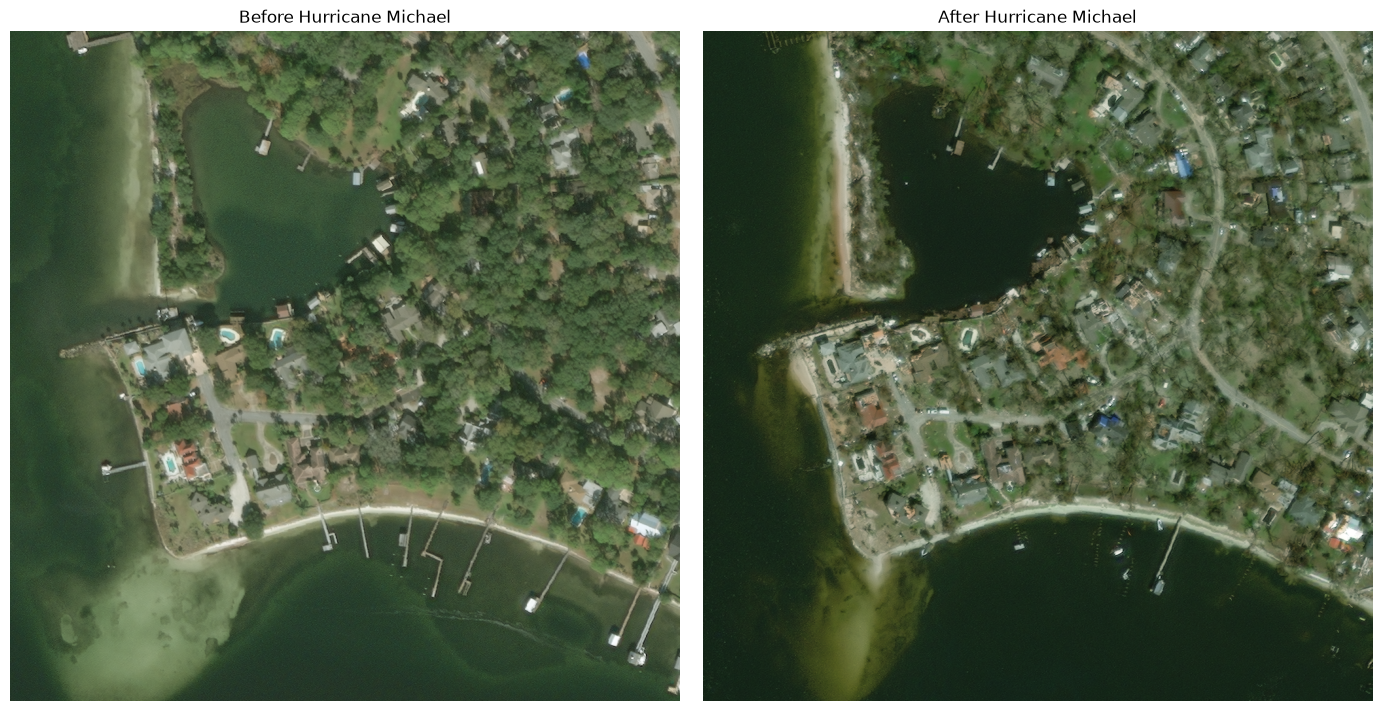

In [2]:
# Load the paired images for this test scene.
scene_id = "hurricane_michael_00000012_disaster"
pre_path = root / "examples/hurricane_michael_00000012_pre_disaster.png"
post_path = root / "examples/hurricane_michael_00000012_post_disaster.png"
pre_image = Image.open(pre_path).convert("RGB")
post_image = Image.open(post_path).convert("RGB")
assert pre_image.size == post_image.size == (1024, 1024)

# Display the original images before adding any predictions.
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, image, title in zip(axes, [pre_image, post_image], ["Before Hurricane Michael", "After Hurricane Michael"]):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Run SIREN

SIREN detects buildings and road segments in the pre-disaster image. It uses features from both images to predict damage, destruction and road blockage, and features from the pre-disaster image to predict residential use and surrounding vegetation.

The result, `scene`, stores each entity's ID, geometry and classifier probabilities. The query programs below read this record to calculate their answers.


In [3]:
# Load the shared image encoder, entity extraction models and visual classifiers.
pipeline = load_pipeline(root / "configs/assets.json", device)

# Each image becomes a [3, 1024, 1024] RGB tensor with values in [0, 1].
pre = torch.from_numpy(np.array(pre_image)).permute(2, 0, 1).float().div(255).to(device)
post = torch.from_numpy(np.array(post_image)).permute(2, 0, 1).float().div(255).to(device)
# Run inference without tracking gradients.
with torch.inference_mode():
    scene = pipeline.run(
        pre, post, chip_id=scene_id, split="test", disaster_id="hurricane_michael"
    )

# Query programs read these records; reference labels are not used for inference.
buildings = scene["entities"]["buildings"]
roads = scene["entities"]["roads"]
print(f"Detected {len(buildings)} buildings and {len(roads)} road segments.")


Detected 48 buildings and 6 road segments.


## 3. Inspect the predictions

Both panels show predictions over the post-disaster image. Building boxes are red for destruction, orange for damage without destruction, and blue when neither classifier passes its threshold. These colors show model predictions, not reference annotations.

Road lines use the road-access threshold; the blocked-road counting query uses a separate threshold. Both are set in `src/siren/settings.py`.


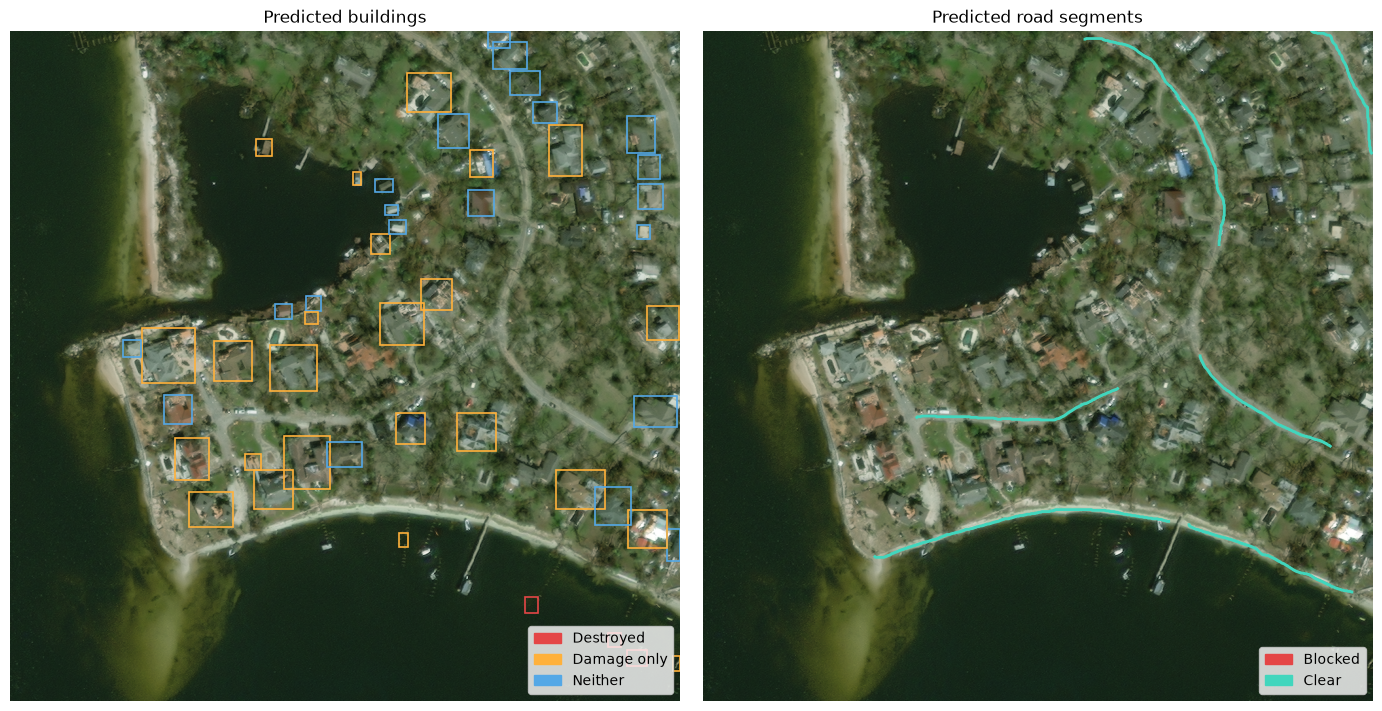

In [4]:
def has_concept(entity, concept):
    """Apply the query's threshold to an entity's classifier probability."""
    score_key, threshold = SCORES[concept]
    return entity["attributes"][score_key] >= threshold

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax in axes:
    ax.imshow(post_image)
    ax.axis("off")

# Give destruction priority when both damage classifiers pass their thresholds.
for building in buildings:
    if has_concept(building, "destroyed"):
        color = "#e44646"
    elif has_concept(building, "damaged"):
        color = "#ffb13b"
    else:
        color = "#54a8e6"
    # Bounding boxes store the top-left and bottom-right pixel coordinates.
    x1, y1, x2, y2 = building["geometry"]["bbox_xyxy"]
    rectangle = Rectangle(
        (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.2
    )
    axes[0].add_patch(rectangle)

# Road geometry is stored as a sequence of centerline points in image pixels.
for road in roads:
    points = np.asarray(road["geometry"]["centerline_xy"])
    color = "#e44646" if has_concept(road, "blocked") else "#41d6bd"
    axes[1].plot(points[:, 0], points[:, 1], color=color, linewidth=2)

building_colors = [("#e44646", "Destroyed"), ("#ffb13b", "Damage only"), ("#54a8e6", "Neither")]
road_colors = [("#e44646", "Blocked"), ("#41d6bd", "Clear")]
for ax, title, colors in zip(
    axes, ["Predicted buildings", "Predicted road segments"], [building_colors, road_colors]
):
    ax.set_title(title)
    ax.legend(handles=[Patch(color=c, label=label) for c, label in colors], loc="lower right")
plt.tight_layout()
plt.show()


## 4. Answer the counting questions

For each of the eight benchmark questions, `count_program` builds a program and `execute` runs it on `scene`. Each program selects entities, checks the requested conditions and counts the matches.

“Near” means within 50 pixels (40 m at 0.8 m per pixel). “Large” means a footprint of at least 2,000 square pixels (1,280 m²). The table shows the predicted count for each question.


In [5]:
# Each program selects entities, applies its conditions and counts those remaining.
answers = {}
for name in COUNT_QUERIES:
    program = count_program(name)
    # The executor returns the answer in value and intermediate results in trace.
    answers[name] = execute(program, scene)["value"]

pd.DataFrame([
    {"Question": name.replace("_", " ").capitalize(), "Predicted count": value}
    for name, value in answers.items()
])


,Question,Predicted count
0,Damaged buildings,27
1,Destroyed buildings,3
2,Blocked roads,0
3,Damaged buildings without clear road,18
4,Destroyed buildings without intact neighbor,3
5,Large destroyed buildings,0
6,Destroyed residential buildings,3
7,Destroyed buildings surrounded by vegetation,0


### Compare with reference counts

Reference counts are available for six questions in this example. They are loaded here for comparison and were not used to make the predictions. `absolute_error` is the absolute difference between the predicted and reference counts.

This is one test scene; the paper reports results across the test set.


In [6]:
# Keep only reference counts for the image pair used above.
references = pd.read_csv(root / "examples/reference_counts.csv")
references = references[references["chip_id"] == scene_id].copy()
# Match predictions to reference rows by question name.
references["prediction"] = references["question"].map(answers)
references["absolute_error"] = (references["prediction"] - references["count"]).abs()
comparison = references.rename(columns={"count": "reference_count"})
comparison[["question", "reference_count", "prediction", "absolute_error"]]

,question,reference_count,prediction,absolute_error
0,damaged_buildings,23,27,4
1,destroyed_buildings,6,3,3
2,blocked_roads,0,0,0
3,damaged_buildings_without_clear_road,20,18,2
4,destroyed_buildings_without_intact_neighbor,5,3,2
5,large_destroyed_buildings,0,0,0


## 5. Follow a spatial query

**How many damaged buildings have no nearby clear road?**

The program:

1. Selects buildings classified as damaged.
2. Selects road segments classified as clear.
3. Keeps damaged buildings with no clear road within 50 pixels.
4. Counts the remaining buildings.

The printed program lists these operations. Each step has an `id`; later steps use that ID to refer to its result. The trace table underneath shows what each step returned.


In [7]:
# Inspect the exact program used for this question in the counting table.
program = count_program("damaged_buildings_without_clear_road")
print(json.dumps(program, indent=2))

# The executor validates the program before applying its steps to the scene.
answer = execute(program, scene)
print(f"Answer: {answer['value']}")
pd.DataFrame(answer["trace"])


{
  "format": "siren.program",
  "steps": [
    {
      "id": "all",
      "op": "select",
      "kind": "buildings"
    },
    {
      "id": "filter_0",
      "op": "filter",
      "source": "all",
      "concept": "damaged",
      "negate": false
    },
    {
      "id": "targets",
      "op": "select",
      "kind": "roads"
    },
    {
      "id": "eligible",
      "op": "filter",
      "source": "targets",
      "concept": "clear",
      "negate": false
    },
    {
      "id": "related",
      "op": "relate",
      "source": "filter_0",
      "target": "eligible",
      "distance_px": 50,
      "policy": "footprint_or_centerline",
      "mode": "none"
    },
    {
      "id": "answer",
      "op": "count",
      "source": "related"
    }
  ],
  "output": "answer"
}
Answer: 18


,id,op,value,unit
0,all,select,"[building:000001, building:000002, building:000003, building:000004, building:000005, building:000006, building:000007, building:000008, building:000009, building:000010, building:000011, building:000012, building:000013, building:000014, building:000015, building:000016, building:000017, building:000018, building:000019, building:000020, building:000021, building:000022, building:000023, building:000024, building:000025, building:000026, building:000027, building:000028, building:000029, building:000030, building:000031, building:000032, building:000033, building:000034, building:000035, building:000036, building:000037, building:000038, building:000039, building:000040, building:000041, building:000042, building:000043, building:000044, building:000045, building:000046, building:000047, building:000048]",NaN
1,filter_0,filter,"[building:000001, building:000002, building:000004, building:000005, building:000006, building:000007, building:000008, building:000009, building:000010, building:000011, building:000012, building:000013, building:000016, building:000017, building:000018, building:000020, building:000023, building:000024, building:000026, building:000028, building:000029, building:000030, building:000031, building:000038, building:000039, building:000042, building:000044]",NaN
2,targets,select,"[road:000001, road:000002, road:000003, road:000004, road:000005, road:000006]",NaN
3,eligible,filter,"[road:000001, road:000002, road:000003, road:000004, road:000005, road:000006]",NaN
4,related,relate,"[building:000002, building:000004, building:000005, building:000006, building:000008, building:000012, building:000016, building:000017, building:000018, building:000023, building:000024, building:000026, building:000029, building:000030, building:000038, building:000039, building:000042, building:000044]",NaN
5,answer,count,18,entities


## 6. Try other calculations

The same entity records also support fractions, densities, comparisons and distances. These examples use fixed programs from `paper_example`.

The fraction divides destroyed buildings by all detected buildings. Density divides the destroyed-building count by the full image area in km². The left–right comparison calculates the destroyed fraction within each half separately. Distances are measured between entity geometries and converted to meters using the image scale.

If no blocked road is predicted, the nearest-building question has no matching pair.


In [8]:
# Supply the image size and DisasterM3's reported scale (0.8 m per pixel) for area and distance calculations.
context = {
    "image_width_px": pre_image.width,
    "valid_area_px": pre_image.width * pre_image.height,
    "pixel_size_m": 0.8,
}
questions = {
    "fraction": "What fraction of buildings are destroyed?",
    "density": "How many destroyed buildings are there per km²?",
    "comparison": "Is the destroyed fraction greater on the left than on the right?",
    "threshold": "Are at least 10 buildings destroyed?",
    "nearest": "Which building is closest to a blocked road?",
}
examples = {}
rows = []
for kind, question in questions.items():
    result = execute(paper_example(kind), scene, context=context)
    value = examples[kind] = result["value"]
    # Keep the raw result in examples; use plain language in the displayed table.
    display_value = value
    if kind == "comparison":
        display_value = {"greater": "Higher on the left", "less": "Higher on the right",
                         "equal": "Equal on both sides"}.get(value, "Undefined")
    elif kind == "nearest" and not value:
        display_value = "No building–blocked-road pair found"
    rows.append({"Question": question, "Answer": display_value})

# Select a predicted damaged building by ID for a specific distance question.
damaged_ids = [b["id"] for b in buildings if has_concept(b, "damaged")]
if damaged_ids:
    # Use the first damaged building in the stored entity order.
    selected_id = damaged_ids[0]
    program = paper_example("distance", entity_id=selected_id)
    examples["distance"] = execute(program, scene, context=context)["value"]
    rows.append({"Question": f"How far is {selected_id} from its nearest clear road (m)?",
                 "Answer": examples["distance"]})
pd.DataFrame(rows)


,Question,Answer
0,What fraction of buildings are destroyed?,0.0625
1,How many destroyed buildings are there per km²?,4.470348
2,Is the destroyed fraction greater on the left than on the right?,Higher on the right
3,Are at least 10 buildings destroyed?,False
4,Which building is closest to a blocked road?,No building–blocked-road pair found
5,How far is building:000001 from its nearest clear road (m)?,26.311741


## 7. Ask your own question (optional)

Here, a language model translates a question into a program using the supported functions. The Python executor validates the program and calculates the answer from `scene`.

This example uses Claude Sonnet 4.6. Change `provider` and `model` to use another supported API model. The model receives the question and function definitions, not the images or reference labels.

Set `use_language_model = True` to run this step. It requires the `language` extra and the provider's API key (`ANTHROPIC_API_KEY` for this example). The saved run leaves this API call off.


In [9]:
use_language_model = False
provider = "anthropic"
model = "claude-sonnet-4-6"
question = "Among residential buildings, what fraction were destroyed?"

if use_language_model:
    from siren.language.compiler import compile_question, execute_compiled
    # Ask the language model to select and combine the available operations.
    compiled = compile_question(question, provider=provider, model=model)
    print(json.dumps(compiled["program"], indent=2))
    # If no supported program is returned, show the explanation.
    if compiled["program"] is None:
        print(compiled["reason"])
    else:
        # Calculate the answer locally from the predicted entities.
        print(execute_compiled(compiled, scene, context=context)["value"])
else:
    print("Optional language-model call is off.")

Optional language-model call is off.


## 8. Save the predictions

Save two JSON files in `outputs/demo/`: the scene record with entity geometry and probabilities, and the eight predicted counts.


In [10]:
output = root / "outputs/demo"
output.mkdir(parents=True, exist_ok=True)
# Save the full scene record and the smaller question-to-count dictionary.
(output / f"{scene_id}.json").write_text(json.dumps(scene, indent=2))
(output / "counts.json").write_text(json.dumps(answers, indent=2))
print("Saved entity records and counts in outputs/demo/.")

Saved entity records and counts in outputs/demo/.
